# Semana 3 Herencia polimorfismo y sustitución

Implementar una planilla heterogénea de personal, comprobar un contrato común y justificar las relaciones de herencia del proyecto hotelero.

Identificador S3-001. Completar ApellidoNombre antes de entregar. Solución elaborada con asistencia de IA. No equivale a una sustentación realizada.


## Preparar archivos

Las celdas writefile guardan las fuentes visibles en el entorno de Colab. Ejecutarlas en orden. Se requiere Python 3.12 o superior y g++ con C++17.


In [ ]:
from pathlib import Path
for carpeta in ["python", "cpp", "tests", ".build", "evidencias"]:
    Path(carpeta).mkdir(exist_ok=True)


### python\__init__.py

In [ ]:
%%writefile python/__init__.py


### python\hotel_base.py

In [ ]:
%%writefile python/hotel_base.py
"""Modelo inicial del proyecto hotelero correspondiente a la semana 2."""

from datetime import date
from math import isfinite


def texto(valor):
    if not isinstance(valor, str) or not valor.strip():
        raise ValueError("Texto no vacio requerido")
    return valor


def entero(valor, minimo, maximo):
    if type(valor) is not int or not minimo <= valor <= maximo:
        raise ValueError("Entero fuera de rango")
    return valor


class Huesped:
    def __init__(self, identificador, nombre, documento):
        self.__id = texto(identificador)
        self.nombre = nombre
        self.documento = documento

    @property
    def id(self):
        return self.__id

    @property
    def nombre(self):
        return self.__nombre

    @nombre.setter
    def nombre(self, valor):
        self.__nombre = texto(valor)

    @property
    def documento(self):
        return self.__documento

    @documento.setter
    def documento(self, valor):
        if (
            not isinstance(valor, str)
            or len(valor) != 8
            or not valor.isascii()
            or not valor.isdigit()
        ):
            raise ValueError("DNI debe tener ocho digitos ASCII")
        self.__documento = valor

    @property
    def etiqueta(self):
        return f"{self.id} {self.nombre}"

    def actualizar_documento(self, documento):
        self.documento = documento


class Habitacion:
    def __init__(self, numero, tipo, capacidad, tarifa):
        self.__numero = entero(numero, 1, 9999)
        self.__ocupantes = 0
        self.tipo = tipo
        self.capacidad = capacidad
        self.tarifa = tarifa

    @property
    def numero(self):
        return self.__numero

    @property
    def tipo(self):
        return self.__tipo

    @tipo.setter
    def tipo(self, valor):
        self.__tipo = texto(valor)

    @property
    def capacidad(self):
        return self.__capacidad

    @capacidad.setter
    def capacidad(self, valor):
        entero(valor, 1, 10)
        if valor < self.__ocupantes:
            raise ValueError("Capacidad menor que ocupantes")
        self.__capacidad = valor

    @property
    def tarifa(self):
        return self.__tarifa

    @tarifa.setter
    def tarifa(self, valor):
        if (
            isinstance(valor, bool)
            or not isinstance(valor, (float, int))
            or not isfinite(valor)
            or valor <= 0
        ):
            raise ValueError("Tarifa positiva finita requerida")
        self.__tarifa = float(valor)

    @property
    def plazas_libres(self):
        return self.capacidad - self.__ocupantes

    def alojar(self, cantidad):
        entero(cantidad, 1, 10)
        if cantidad > self.plazas_libres:
            raise RuntimeError("Sin plazas")
        self.__ocupantes += cantidad

    def liberar(self):
        self.__ocupantes = 0

    def precio_noche(self):
        return self.tarifa


class Reserva:
    def __init__(self, codigo, entrada, salida):
        self.__codigo = texto(codigo)
        self.__entrada = date.fromisoformat(entrada)
        self.__salida = date.fromisoformat(salida)
        if self.__salida <= self.__entrada:
            raise ValueError("Salida debe ser posterior")
        self.__estado = "REGISTRADA"

    @property
    def codigo(self):
        return self.__codigo

    @property
    def entrada(self):
        return self.__entrada.isoformat()

    @property
    def salida(self):
        return self.__salida.isoformat()

    @property
    def noches(self):
        return (self.__salida - self.__entrada).days

    @property
    def estado(self):
        return self.__estado

    def confirmar(self):
        if self.estado != "REGISTRADA":
            raise RuntimeError("Confirmacion no permitida")
        self.__estado = "CONFIRMADA"

    def anular(self):
        if self.estado == "ANULADA":
            raise RuntimeError("Reserva ya anulada")
        self.__estado = "ANULADA"


### python\hotel_herencia.py

In [ ]:
%%writefile python/hotel_herencia.py
"""Semana 3: las categorías son habitaciones y conservan el contrato de precio."""

from .hotel_base import Habitacion


class HabitacionSimple(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Simple", 1, tarifa)

    def precio_noche(self):
        return self.tarifa


class HabitacionDoble(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Doble", 2, tarifa)

    def precio_noche(self):
        return self.tarifa * 1.5


class Suite(Habitacion):
    def __init__(self, numero, tarifa=100):
        super().__init__(numero, "Suite", 4, tarifa)

    def precio_noche(self):
        return self.tarifa * 2


def cotizar_habitaciones(habitaciones):
    return [h.precio_noche() for h in habitaciones]


### python\main.py

In [ ]:
%%writefile python/main.py
from .solucion import demo

if __name__ == "__main__":
    print("\n".join(demo()))


### python\solucion.py

In [ ]:
%%writefile python/solucion.py
"""Herencia justificada, despacho dinámico y contraejemplo de Liskov."""

from abc import ABC, abstractmethod
from math import isfinite
import re
from typing import override


class PersonalUniversitario(ABC):
    TARIFA_HORA_BASE = 75.0

    def __init__(self, dni, nombres, apellidos):
        if not re.fullmatch(r"[0-9]{8}", dni):
            raise ValueError("DNI invalido")
        if not nombres.strip() or not apellidos.strip():
            raise ValueError("Nombre vacio")
        self.__dni, self._nombres, self._apellidos = dni, nombres, apellidos

    @property
    def dni(self):
        return self.__dni

    @property
    def nombre_completo(self):
        return f"{self._apellidos}, {self._nombres}"

    @abstractmethod
    def calcular_remuneracion(self):
        raise NotImplementedError

    def __str__(self):
        return f"{self.nombre_completo}: S/ {self.calcular_remuneracion():.2f}"


class Docente(PersonalUniversitario):
    FACTORES = {"Auxiliar": 1.0, "Asociado": 1.4, "Principal": 1.8}

    def __init__(self, dni, nombres, apellidos, horas, categoria):
        super().__init__(dni, nombres, apellidos)
        if type(horas) is not int or not 1 <= horas <= 40:
            raise ValueError("Horas fuera de 1 a 40")
        if categoria not in self.FACTORES:
            raise ValueError("Categoria invalida")
        self._horas, self._categoria = horas, categoria

    @override
    def calcular_remuneracion(self):
        return self._horas * self.TARIFA_HORA_BASE * self.FACTORES[self._categoria]


class Administrativo(PersonalUniversitario):
    def __init__(self, dni, nombres, apellidos, salario_base, bono=0):
        super().__init__(dni, nombres, apellidos)
        if not isfinite(salario_base) or salario_base <= 0:
            raise ValueError("Salario positivo requerido")
        if not isfinite(bono) or bono < 0:
            raise ValueError("Bono no negativo requerido")
        self._salario_base, self._bono = salario_base, bono

    @override
    def calcular_remuneracion(self):
        return self._salario_base + self._bono


class Investigador(PersonalUniversitario):
    def __init__(self, dni, nombres, apellidos, proyectos):
        super().__init__(dni, nombres, apellidos)
        if type(proyectos) is not int or proyectos < 1:
            raise ValueError("Proyectos positivos requeridos")
        self._proyectos = proyectos

    @override
    def calcular_remuneracion(self):
        return self._proyectos * 1500.0


def planilla(personal):
    """El cliente imprime el resultado; el cálculo no pregunta el subtipo."""
    filas = [str(persona) for persona in personal]
    return filas + [f"TOTAL={sum(p.calcular_remuneracion() for p in personal):.2f}"]


def verificar_contrato_personal(persona):
    valor = persona.calcular_remuneracion()
    return (
        bool(persona.nombre_completo)
        and isfinite(valor)
        and valor > 0
        and persona.nombre_completo in str(persona)
    )


class Figura(ABC):
    @abstractmethod
    def area(self):
        raise NotImplementedError


class Rectangulo(Figura):
    def __init__(self, ancho, alto):
        self.set_ancho(ancho)
        self.set_alto(alto)

    def set_ancho(self, v):
        if not isfinite(v) or v <= 0:
            raise ValueError("Dimension invalida")
        self._ancho = v

    def set_alto(self, v):
        if not isfinite(v) or v <= 0:
            raise ValueError("Dimension invalida")
        self._alto = v

    def area(self):
        return self._ancho * self._alto


class CuadradoIncompatible(Rectangulo):
    """Contraejemplo intencional: rompe la independencia de ancho y alto."""

    def __init__(self, lado):
        super().__init__(lado, lado)

    def set_ancho(self, v):
        super().set_ancho(v)
        self._alto = v

    def set_alto(self, v):
        super().set_alto(v)
        self._ancho = v


class Cuadrado(Figura):
    """Alternativa correcta: comparte el contrato área, no setters independientes."""

    def __init__(self, lado):
        if not isfinite(lado) or lado <= 0:
            raise ValueError("Lado invalido")
        self._lado = lado

    def area(self):
        return self._lado**2


def comprobar_rectangulo(figura):
    figura.set_ancho(4)
    figura.set_alto(5)
    assert figura.area() == 20, "Se rompio el contrato de dimensiones independientes"


def datos():
    return [
        Docente("12345678", "Juan Carlos", "Mamani Quispe", 16, "Asociado"),
        Docente("23456789", "Maria Elena", "Quispe Torres", 12, "Principal"),
        Administrativo("34567890", "Pedro", "Huanca Lazo", 2800, 350),
        Investigador("45678901", "Ana Lucia", "Flores Ramos", 2),
    ]


def demo():
    personal = datos()
    return planilla(personal) + [
        f"CONTRATOS={sum(verificar_contrato_personal(p) for p in personal)}"
    ]


### cpp\comun.hpp

In [ ]:
%%writefile cpp/comun.hpp
#pragma once
#include <algorithm>
#include <cassert>
#include <cmath>
#include <ctime>
#include <functional>
#include <iomanip>
#include <iostream>
#include <memory>
#include <regex>
#include <sstream>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

inline void exigir(bool condicion) {
    if (!condicion) {
        throw std::runtime_error("No coincide con el contrato esperado");
    }
}
template <class Error = std::exception, class F> void debeFallar(F accion) {
    bool fallo = false;
    try {
        accion();
    } catch (const Error &) {
        fallo = true;
    }
    exigir(fallo);
}
struct Pruebas {
    int total = 0, correctas = 0;
    template <class F> void caso(const std::string &nombre, F accion) {
        ++total;
        try {
            accion();
            ++correctas;
            std::cout << "OK " << nombre << '\n';
        } catch (const std::exception &e) {
            std::cerr << "FALLO " << nombre << ": " << e.what() << '\n';
        }
    }
    int terminar() const {
        std::cout << correctas << '/' << total << " pruebas aprobadas\n";
        return total == correctas ? 0 : 1;
    }
};
inline void textoValido(const std::string &v) {
    if (v.find_first_not_of(" \t\r\n") == std::string::npos) {
        throw std::invalid_argument("Texto vacio");
    }
}
inline void positivo(double v) {
    if (!std::isfinite(v) || v <= 0) {
        throw std::invalid_argument("Valor positivo requerido");
    }
}
inline bool bisiesto(int y) {
    return y % 4 == 0 && (y % 100 != 0 || y % 400 == 0);
}
inline int ordinal(const std::string &fecha) {
    if (!std::regex_match(fecha, std::regex("[0-9]{4}-[0-9]{2}-[0-9]{2}"))) {
        throw std::invalid_argument("Fecha ISO requerida");
    }
    int y = std::stoi(fecha.substr(0, 4)), m = std::stoi(fecha.substr(5, 2)),
        d = std::stoi(fecha.substr(8, 2));
    const int dias[] = {31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31};
    if (y < 1 || m < 1 || m > 12 || d < 1 || d > dias[m - 1] + (m == 2 && bisiesto(y))) {
        throw std::invalid_argument("Fecha inexistente");
    }
    int n = 365 * (y - 1) + (y - 1) / 4 - (y - 1) / 100 + (y - 1) / 400 + d;
    for (int i = 1; i < m; ++i) {
        n += dias[i - 1] + (i == 2 && bisiesto(y));
    }
    return n;
}
inline std::string hoyISO() {
    auto ahora = std::time(nullptr);
    auto *fecha = std::localtime(&ahora);
    if (!fecha) {
        throw std::runtime_error("Reloj no disponible");
    }
    std::ostringstream out;
    out << std::put_time(fecha, "%Y-%m-%d");
    return out.str();
}


### cpp\hotel_base.hpp

In [ ]:
%%writefile cpp/hotel_base.hpp
#pragma once
#include "comun.hpp"

class Huesped {
    std::string id_, nombre_, documento_;

  public:
    Huesped(std::string id, std::string nombre, std::string documento) : id_(std::move(id)) {
        textoValido(id_);
        setNombre(nombre);
        setDocumento(documento);
    }
    const std::string &id() const noexcept {
        return id_;
    }
    const std::string &nombre() const noexcept {
        return nombre_;
    }
    const std::string &documento() const noexcept {
        return documento_;
    }
    void setNombre(const std::string &v) {
        textoValido(v);
        nombre_ = v;
    }
    void setDocumento(const std::string &v) {
        if (!std::regex_match(v, std::regex("[0-9]{8}"))) {
            throw std::invalid_argument("DNI invalido");
        }
        documento_ = v;
    }
    std::string etiqueta() const {
        return id_ + " " + nombre_;
    }
    void actualizarDocumento(const std::string &v) {
        setDocumento(v);
    }
};

class Habitacion {
    int numero_, capacidad_ = 1, ocupantes_ = 0;
    std::string tipo_;
    double tarifa_ = 1;

  public:
    Habitacion(int numero, const std::string &tipo, int capacidad, double tarifa)
        : numero_(numero) {
        if (numero < 1 || numero > 9999) {
            throw std::invalid_argument("Numero invalido");
        }
        setTipo(tipo);
        setCapacidad(capacidad);
        setTarifa(tarifa);
    }
    virtual ~Habitacion() = default;
    int numero() const noexcept {
        return numero_;
    }
    int capacidad() const noexcept {
        return capacidad_;
    }
    const std::string &tipo() const noexcept {
        return tipo_;
    }
    double tarifa() const noexcept {
        return tarifa_;
    }
    void setTipo(const std::string &v) {
        textoValido(v);
        tipo_ = v;
    }
    void setCapacidad(int v) {
        if (v < 1 || v > 10 || v < ocupantes_) {
            throw std::invalid_argument("Capacidad invalida");
        }
        capacidad_ = v;
    }
    void setTarifa(double v) {
        positivo(v);
        tarifa_ = v;
    }
    int plazasLibres() const noexcept {
        return capacidad_ - ocupantes_;
    }
    void alojar(int cantidad) {
        if (cantidad <= 0 || cantidad > plazasLibres()) {
            throw std::runtime_error("Sin plazas");
        }
        ocupantes_ += cantidad;
    }
    void liberar() noexcept {
        ocupantes_ = 0;
    }
    virtual double precioNoche() const {
        return tarifa_;
    }
};

class Reserva {
    std::string codigo_, entrada_, salida_, estado_ = "REGISTRADA";

  public:
    Reserva(std::string codigo, std::string entrada, std::string salida)
        : codigo_(std::move(codigo)), entrada_(std::move(entrada)), salida_(std::move(salida)) {
        textoValido(codigo_);
        if (ordinal(salida_) <= ordinal(entrada_)) {
            throw std::invalid_argument("Salida debe ser posterior");
        }
    }
    const std::string &codigo() const noexcept {
        return codigo_;
    }
    const std::string &entrada() const noexcept {
        return entrada_;
    }
    const std::string &salida() const noexcept {
        return salida_;
    }
    const std::string &estado() const noexcept {
        return estado_;
    }
    int noches() const {
        return ordinal(salida_) - ordinal(entrada_);
    }
    void confirmar() {
        if (estado_ != "REGISTRADA") {
            throw std::runtime_error("Confirmacion no permitida");
        }
        estado_ = "CONFIRMADA";
    }
    void anular() {
        if (estado_ == "ANULADA") {
            throw std::runtime_error("Reserva ya anulada");
        }
        estado_ = "ANULADA";
    }
};


### cpp\hotel_herencia.hpp

In [ ]:
%%writefile cpp/hotel_herencia.hpp
#pragma once
#include "hotel_base.hpp"
class HabitacionSimple : public Habitacion {
  public:
    explicit HabitacionSimple(int numero, double tarifa = 100)
        : Habitacion(numero, "Simple", 1, tarifa) {}
    double precioNoche() const override {
        return tarifa();
    }
};
class HabitacionDoble : public Habitacion {
  public:
    explicit HabitacionDoble(int numero, double tarifa = 100)
        : Habitacion(numero, "Doble", 2, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 1.5;
    }
};
class Suite : public Habitacion {
  public:
    explicit Suite(int numero, double tarifa = 100) : Habitacion(numero, "Suite", 4, tarifa) {}
    double precioNoche() const override {
        return tarifa() * 2;
    }
};


### cpp\main.cpp

In [ ]:
%%writefile cpp/main.cpp
#include "solucion.hpp"
int main() {
    demo();
}


### cpp\pruebas.cpp

In [ ]:
%%writefile cpp/pruebas.cpp
#include "hotel_herencia.hpp"
#include "solucion.hpp"
#include <type_traits>
int main() {
    Pruebas t;
    t.caso("base abstracta y destructor virtual", [] {
        exigir(std::is_abstract<PersonalUniversitario>::value &&
               std::has_virtual_destructor<PersonalUniversitario>::value);
    });
    t.caso("remuneraciones", [] {
        auto p = datos();
        double esperado[] = {1680, 1620, 3150, 3000};
        for (std::size_t i = 0; i < p.size(); ++i) {
            exigir(std::abs(p[i]->calcularRemuneracion() - esperado[i]) < 0.001);
        }
    });
    t.caso("contratos todos", [] {
        for (const auto &p : datos()) {
            exigir(verificarContrato(*p));
        }
    });
    t.caso("dni", [] { debeFallar([] { Docente d("12", "A", "B", 16, "Asociado"); }); });
    t.caso("horas", [] {
        for (int h : {0, 41}) {
            debeFallar([h] { Docente d("12345678", "A", "B", h, "Asociado"); });
        }
    });
    t.caso("categoria", [] { debeFallar([] { Docente d("12345678", "A", "B", 16, "Otro"); }); });
    t.caso("salario", [] { debeFallar([] { Administrativo a("12345678", "A", "B", 0); }); });
    t.caso("bono no debilita contrato",
           [] { debeFallar([] { Administrativo a("12345678", "A", "B", 2800, -5000); }); });
    t.caso("proyectos", [] { debeFallar([] { Investigador a("12345678", "A", "B", 0); }); });
    t.caso("rectangulo", [] {
        Rectangulo r(2, 2);
        exigir(comprobarRectangulo(r));
    });
    t.caso("violacion intencional detectada", [] {
        CuadradoIncompatible c(2);
        exigir(!comprobarRectangulo(c));
    });
    t.caso("alternativa figura", [] {
        Cuadrado c(5);
        exigir(c.area() == 25);
    });
    t.caso("hotel heterogeneo", [] {
        std::vector<std::unique_ptr<Habitacion>> hs;
        hs.push_back(std::make_unique<HabitacionSimple>(101));
        hs.push_back(std::make_unique<HabitacionDoble>(102));
        hs.push_back(std::make_unique<Suite>(103));
        double esperado[] = {100, 150, 200};
        for (std::size_t i = 0; i < hs.size(); ++i) {
            exigir(hs[i]->precioNoche() == esperado[i]);
        }
    });
    return t.terminar();
}


### cpp\solucion.hpp

In [ ]:
%%writefile cpp/solucion.hpp
#pragma once
#include "comun.hpp"

class PersonalUniversitario {
    std::string dni_, nombres_, apellidos_;

  public:
    PersonalUniversitario(std::string dni, std::string nombres, std::string apellidos)
        : dni_(std::move(dni)), nombres_(std::move(nombres)), apellidos_(std::move(apellidos)) {
        if (!std::regex_match(dni_, std::regex("[0-9]{8}"))) {
            throw std::invalid_argument("DNI invalido");
        }
        textoValido(nombres_);
        textoValido(apellidos_);
    }
    virtual ~PersonalUniversitario() = default;
    virtual double calcularRemuneracion() const = 0;
    std::string nombreCompleto() const {
        return apellidos_ + ", " + nombres_;
    }
    std::string descripcion() const {
        std::ostringstream out;
        out << nombreCompleto() << ": S/ " << std::fixed << std::setprecision(2)
            << calcularRemuneracion();
        return out.str();
    }
};
class Docente : public PersonalUniversitario {
    int horas_;
    double factor_;
    static double factor(const std::string &categoria) {
        if (categoria == "Auxiliar") {
            return 1;
        }
        if (categoria == "Asociado") {
            return 1.4;
        }
        if (categoria == "Principal") {
            return 1.8;
        }
        throw std::invalid_argument("Categoria invalida");
    }

  public:
    Docente(std::string dni, std::string nombres, std::string apellidos, int horas,
            const std::string &categoria)
        : PersonalUniversitario(std::move(dni), std::move(nombres), std::move(apellidos)),
          horas_(horas), factor_(factor(categoria)) {
        if (horas < 1 || horas > 40) {
            throw std::invalid_argument("Horas invalidas");
        }
    }
    double calcularRemuneracion() const override {
        return horas_ * 75.0 * factor_;
    }
};
class Administrativo : public PersonalUniversitario {
    double salario_, bono_;

  public:
    Administrativo(std::string dni, std::string nombres, std::string apellidos, double salario,
                   double bono = 0)
        : PersonalUniversitario(std::move(dni), std::move(nombres), std::move(apellidos)),
          salario_(salario), bono_(bono) {
        positivo(salario_);
        if (!std::isfinite(bono_) || bono_ < 0) {
            throw std::invalid_argument("Bono invalido");
        }
    }
    double calcularRemuneracion() const override {
        return salario_ + bono_;
    }
};
class Investigador : public PersonalUniversitario {
    int proyectos_;

  public:
    Investigador(std::string dni, std::string nombres, std::string apellidos, int proyectos)
        : PersonalUniversitario(std::move(dni), std::move(nombres), std::move(apellidos)),
          proyectos_(proyectos) {
        if (proyectos < 1) {
            throw std::invalid_argument("Proyectos invalidos");
        }
    }
    double calcularRemuneracion() const override {
        return proyectos_ * 1500.0;
    }
};
inline bool verificarContrato(const PersonalUniversitario &p) {
    return !p.nombreCompleto().empty() && std::isfinite(p.calcularRemuneracion()) &&
           p.calcularRemuneracion() > 0 &&
           p.descripcion().find(p.nombreCompleto()) != std::string::npos;
}
class Figura {
  public:
    virtual ~Figura() = default;
    virtual double area() const = 0;
};
class Rectangulo : public Figura {
  protected:
    double ancho_, alto_;

  public:
    Rectangulo(double a, double b) : ancho_(a), alto_(b) {
        positivo(a);
        positivo(b);
    }
    virtual void setAncho(double v) {
        positivo(v);
        ancho_ = v;
    }
    virtual void setAlto(double v) {
        positivo(v);
        alto_ = v;
    }
    double area() const override {
        return ancho_ * alto_;
    }
};
class CuadradoIncompatible : public Rectangulo {
  public:
    explicit CuadradoIncompatible(double v) : Rectangulo(v, v) {}
    void setAncho(double v) override {
        positivo(v);
        ancho_ = alto_ = v;
    }
    void setAlto(double v) override {
        positivo(v);
        ancho_ = alto_ = v;
    }
};
class Cuadrado : public Figura {
    double lado_;

  public:
    explicit Cuadrado(double v) : lado_(v) {
        positivo(v);
    }
    double area() const override {
        return lado_ * lado_;
    }
};
inline bool comprobarRectangulo(Rectangulo &r) {
    r.setAncho(4);
    r.setAlto(5);
    return r.area() == 20;
}
inline std::vector<std::unique_ptr<PersonalUniversitario>> datos() {
    std::vector<std::unique_ptr<PersonalUniversitario>> p;
    p.push_back(
        std::make_unique<Docente>("12345678", "Juan Carlos", "Mamani Quispe", 16, "Asociado"));
    p.push_back(
        std::make_unique<Docente>("23456789", "Maria Elena", "Quispe Torres", 12, "Principal"));
    p.push_back(std::make_unique<Administrativo>("34567890", "Pedro", "Huanca Lazo", 2800, 350));
    p.push_back(std::make_unique<Investigador>("45678901", "Ana Lucia", "Flores Ramos", 2));
    return p;
}
inline double planilla(const std::vector<std::unique_ptr<PersonalUniversitario>> &personal) {
    double total = 0;
    for (const auto &p : personal) {
        std::cout << p->descripcion() << '\n';
        total += p->calcularRemuneracion();
    }
    std::cout << "TOTAL=" << std::fixed << std::setprecision(2) << total << '\n';
    return total;
}
inline void demo() {
    auto personal = datos();
    planilla(personal);
    int correctos = 0;
    for (const auto &p : personal) {
        if (verificarContrato(*p)) {
            ++correctos;
        }
    }
    std::cout << "CONTRATOS=" << correctos << '\n';
}


### tests\__init__.py

In [ ]:
%%writefile tests/__init__.py


### tests\test_solucion.py

In [ ]:
%%writefile tests/test_solucion.py
import unittest
from python.solucion import (
    PersonalUniversitario,
    Docente,
    Administrativo,
    Investigador,
    datos,
    planilla,
    verificar_contrato_personal,
    Rectangulo,
    CuadradoIncompatible,
    Cuadrado,
    comprobar_rectangulo,
)
from python.hotel_herencia import HabitacionSimple, HabitacionDoble, Suite, cotizar_habitaciones


class ContratosSemana3(unittest.TestCase):
    def test_base_abstracta(self):
        with self.assertRaises(TypeError):
            PersonalUniversitario("12345678", "A", "B")

    def test_remuneraciones(self):
        self.assertEqual(
            [round(p.calcular_remuneracion(), 2) for p in datos()], [1680, 1620, 3150, 3000]
        )

    def test_planilla_polimorfica(self):
        self.assertEqual(planilla(datos())[-1], "TOTAL=9450.00")

    def test_contrato_todas_subclases(self):
        self.assertTrue(all(verificar_contrato_personal(p) for p in datos()))

    def test_dni_invalido(self):
        with self.assertRaises(ValueError):
            Docente("12", "A", "B", 16, "Asociado")

    def test_horas_limites(self):
        for n in [0, 41]:
            with self.subTest(n=n), self.assertRaises(ValueError):
                Docente("12345678", "A", "B", n, "Asociado")

    def test_categoria(self):
        with self.assertRaises(ValueError):
            Docente("12345678", "A", "B", 16, "Otro")

    def test_salario_y_bono(self):
        for salario, bono in [(0, 0), (2800, -5000), (float("nan"), 0)]:
            with self.subTest(salario=salario), self.assertRaises(ValueError):
                Administrativo("12345678", "A", "B", salario, bono)

    def test_proyectos(self):
        with self.assertRaises(ValueError):
            Investigador("12345678", "A", "B", 0)

    def test_rectangulo_contrato(self):
        comprobar_rectangulo(Rectangulo(2, 2))

    def test_cuadrado_incompatible_falla_como_se_espera(self):
        with self.assertRaises(AssertionError):
            comprobar_rectangulo(CuadradoIncompatible(2))

    def test_figuras_corregidas(self):
        self.assertEqual([f.area() for f in [Rectangulo(4, 5), Cuadrado(5)]], [20, 25])

    def test_hotel_polimorfismo(self):
        hs = [HabitacionSimple(101), HabitacionDoble(102), Suite(103)]
        self.assertEqual(cotizar_habitaciones(hs), [100, 150, 200])
        self.assertTrue(all(h.precio_noche() > 0 for h in hs))


if __name__ == "__main__":
    unittest.main()


## Demostración verificada localmente

La salida incorporada procede de ejecutar estas mismas fuentes en el equipo. Los bloques pueden repetirse en Colab.


In [ ]:
!python -m python.main


Mamani Quispe, Juan Carlos: S/ 1680.00
Quispe Torres, Maria Elena: S/ 1620.00
Huanca Lazo, Pedro: S/ 3150.00
Flores Ramos, Ana Lucia: S/ 3000.00
TOTAL=9450.00
CONTRATOS=4


In [ ]:
!python -m unittest discover -s tests -v


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/main.cpp -o .build/demo
!./.build/demo


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror cpp/pruebas.cpp -o .build/pruebas
!./.build/pruebas


## Análisis y reflexión

### Por qué falla el cuadrado
La matemática clasifica figuras por sus propiedades; la interfaz mutable de Rectangulo promete cambios independientes de ancho y alto. El cuadrado no puede mantener ambas promesas. La alternativa comparte solo Figura.area y mantiene ambas clases separadas.

### Decisión en el hotel
Simple, Doble y Suite son habitaciones y preservan una cotización positiva. Una reserva tiene un huésped y una habitación; no debe heredar de ellos. La relación se modela mediante referencias o composición según la vida de cada objeto.

### Destructor virtual
Al destruir un objeto derivado a través de un puntero a una base sin destructor virtual se incurre en comportamiento indefinido. La base polimórfica declara un destructor virtual y unique_ptr gestiona la liberación.

### Duck typing y tipos estrictos
Python admite objetos que cumplen operaciones sin pertenecer a una jerarquía nominal; facilita pruebas y adaptadores, con errores potencialmente tardíos. C++ verifica el contrato declarado durante compilación, a costa de mayor declaración de tipos. ABC y las pruebas hacen explícitas las expectativas en Python.

## diagrama clases

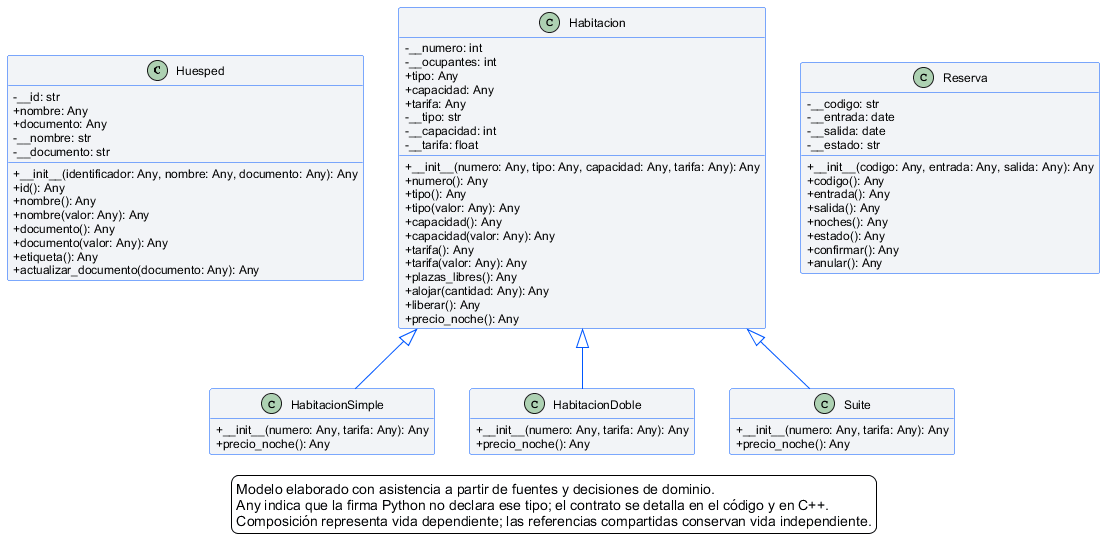

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))


## resumen informe

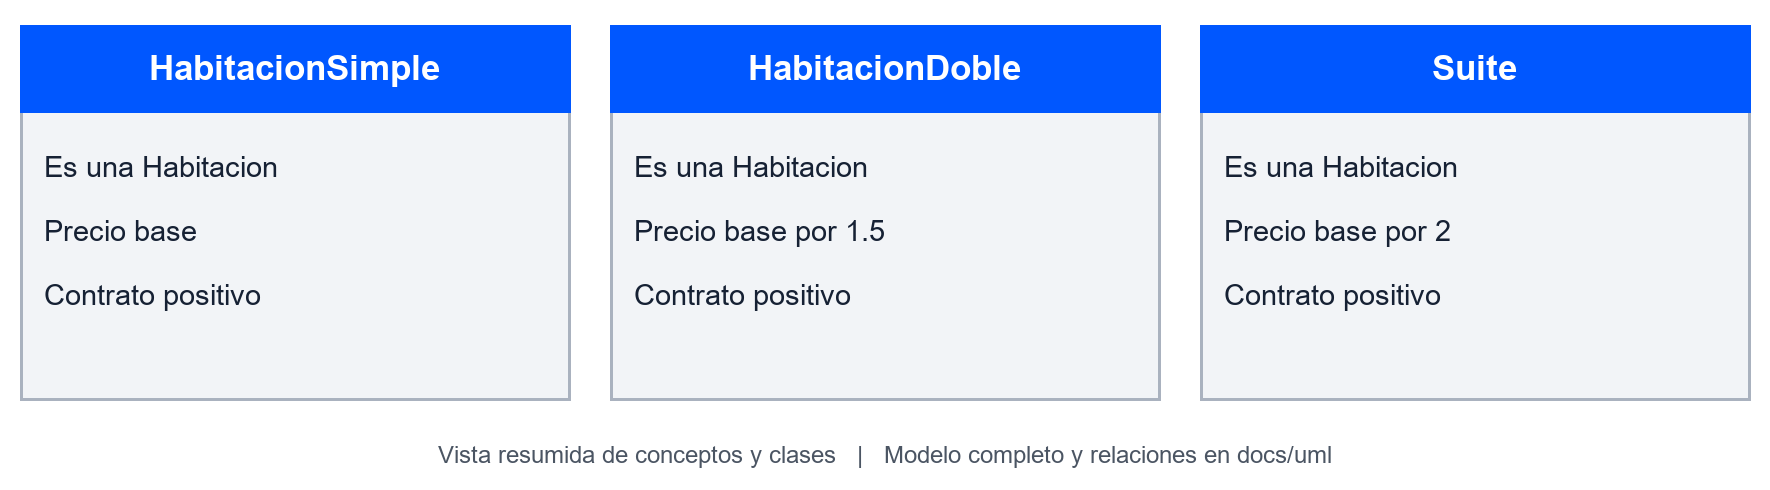

In [ ]:
import base64
from IPython.display import display, Image
display(Image(data=base64.b64decode('...')))
